# 🇹🇷 Türkiye'de Enflasyon ve Döviz Kuru Analizi (2005–2025)

Bu defterde üç soruya cevap arıyoruz:

1. Türkiye'nin enflasyonu ABD ve Euro Bölgesi'nden ne kadar ayrıştı?
2. Döviz kurundaki artış enflasyonla ne kadar örtüşüyor?
3. **Satın alma gücü paritesine (PPP)** göre TL olması gerekenden ucuz mu, pahalı mı?

**Veri:** Dünya Bankası yıllık TÜFE enflasyonu (`FP.CPI.TOTL.ZG`) ve Avrupa Merkez Bankası referans kurları ([Frankfurter](https://frankfurter.dev)).
Veri `src/veri.py` ile çekilip `veri/` klasörüne kaydedilir; defter kayıtlı veriyle çalıştığı için sonuçlar tekrarlanabilir.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from src.veri import veriyi_yukle

enflasyon, kur = veriyi_yukle()
kur = kur.loc["2005":]  # ECB serisi 2004'ün son iş gününden başlıyor

RENK = {"Türkiye": "#C8102E", "ABD": "#1F5AA6", "Euro Bölgesi": "#E3A21A",
        "USD/TRY": "#1F5AA6", "EUR/TRY": "#E3A21A", "gri": "#8A8F98"}
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 13, "font.size": 10.5,
})

def kaydet(fig, ad):
    fig.tight_layout()
    fig.savefig(f"grafikler/{ad}.png", bbox_inches="tight", facecolor="white")

enflasyon.round(1)

,ABD,Euro Bölgesi,Türkiye
yil,,,
2005,3.4,2.6,8.2
2006,3.2,2.8,9.6
2007,2.9,2.5,8.8
2008,3.8,4.2,10.4
2009,-0.4,0.5,6.3
2010,1.6,1.5,8.6
2011,3.2,3.3,6.5
2012,2.1,2.6,8.9
2013,1.5,1.2,7.5


## 1. Enflasyon: Türkiye, ABD ve Euro Bölgesi

Yıllık enflasyon, tüketici fiyat endeksinin (TÜFE) bir önceki yılın ortalamasına göre değişimidir:

$$\pi_t = \frac{P_t - P_{t-1}}{P_{t-1}} \times 100$$

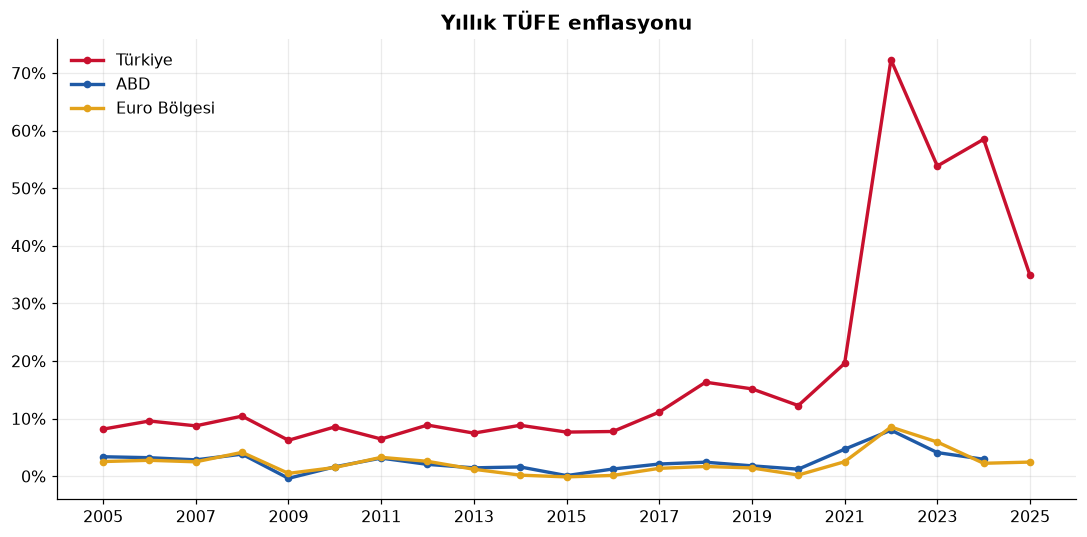

,ABD,Euro Bölgesi,Türkiye
2005–2017,2.0,1.8,8.5
2018–2021,2.5,1.5,15.8
2022–2025,5.0,4.8,54.9


In [2]:
fig, ax = plt.subplots()
for ulke in ["Türkiye", "ABD", "Euro Bölgesi"]:
    ax.plot(enflasyon.index, enflasyon[ulke], marker="o", ms=4, lw=2.2,
            color=RENK[ulke], label=ulke)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Yıllık TÜFE enflasyonu")
ax.set_xticks(range(2005, 2026, 2))
ax.legend(frameon=False)
kaydet(fig, "1_enflasyon")
plt.show()

donemler = {"2005–2017": (2005, 2017), "2018–2021": (2018, 2021), "2022–2025": (2022, 2025)}
pd.DataFrame({ad: enflasyon.loc[a:b].mean() for ad, (a, b) in donemler.items()}).T.round(1)

## 2. Döviz kurları

Kurun 20 yılda kaç kat arttığını tek grafikte okuyabilmek için dikey eksen **logaritmik**:
eşit aralıklar eşit *oransal* değişimi gösterir.

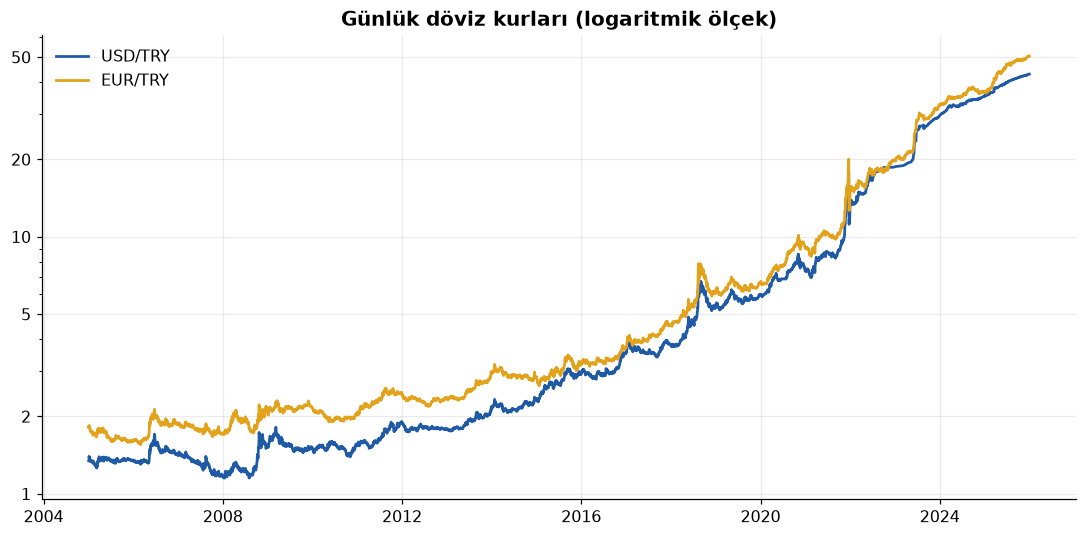

USD/TRY yıllık ortalama: 2005: 1.35 → 2025: 39.57  (29.3 kat)


In [3]:
fig, ax = plt.subplots()
for parite in ["USD/TRY", "EUR/TRY"]:
    ax.plot(kur.index, kur[parite], lw=1.8, color=RENK[parite], label=parite)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks([1, 2, 5, 10, 20, 50])
ax.set_title("Günlük döviz kurları (logaritmik ölçek)")
ax.legend(frameon=False)
kaydet(fig, "2_kurlar")
plt.show()

yillik_kur = kur.groupby(kur.index.year).mean()
yillik_kur.index.name = "yil"
kur_degisim = yillik_kur.pct_change() * 100
ilk, son = yillik_kur.index[0], yillik_kur.index[-1]
print(f"USD/TRY yıllık ortalama: {ilk}: {yillik_kur.loc[ilk, 'USD/TRY']:.2f} → {son}: {yillik_kur.loc[son, 'USD/TRY']:.2f}"
      f"  ({yillik_kur.loc[son, 'USD/TRY'] / yillik_kur.loc[ilk, 'USD/TRY']:.1f} kat)")

## 3. Kur artışı ve enflasyon aynı yönde mi?

Her yıl için ortalama USD/TRY kurunun yıllık değişimini, Türkiye enflasyonuyla yan yana koyuyoruz.

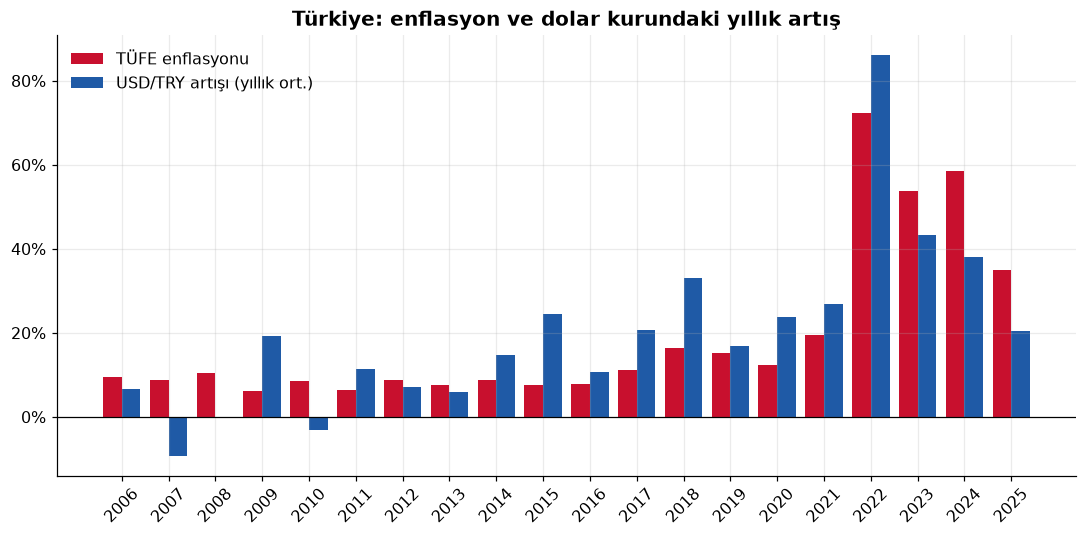

Aynı yıl korelasyonu:                     r = 0.83
Geçen yılın kur artışı → bu yılın enflasyonu: r = 0.69


In [4]:
karsilastirma = pd.DataFrame({
    "TÜFE enflasyonu": enflasyon["Türkiye"],
    "USD/TRY artışı": kur_degisim["USD/TRY"],
}).loc[2006:2025]

fig, ax = plt.subplots()
x = np.arange(len(karsilastirma))
ax.bar(x - 0.2, karsilastirma["TÜFE enflasyonu"], 0.4, color=RENK["Türkiye"], label="TÜFE enflasyonu")
ax.bar(x + 0.2, karsilastirma["USD/TRY artışı"], 0.4, color=RENK["USD/TRY"], label="USD/TRY artışı (yıllık ort.)")
ax.set_xticks(x, karsilastirma.index, rotation=45)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Türkiye: enflasyon ve dolar kurundaki yıllık artış")
ax.legend(frameon=False)
kaydet(fig, "3_enflasyon_kur")
plt.show()

ayni_yil = karsilastirma.corr().iloc[0, 1]
gecikmeli = karsilastirma["TÜFE enflasyonu"].corr(karsilastirma["USD/TRY artışı"].shift(1))
print(f"Aynı yıl korelasyonu:                     r = {ayni_yil:.2f}")
print(f"Geçen yılın kur artışı → bu yılın enflasyonu: r = {gecikmeli:.2f}")

> **Not:** 20 yıllık veriyle hesaplanan korelasyon bir *ilişki* gösterir, nedensellik kanıtlamaz.
> Kurdan fiyatlara geçiş (kur geçişkenliği) iktisatta ayrıca modellenen bir konudur.

## 4. Satın alma gücü paritesi (PPP)

**Göreli PPP**'ye göre iki ülke arasındaki kur, enflasyon farkı kadar değişmelidir:

$$S_t^{\,PPP} = S_{2005} \times \prod_{k=2006}^{t} \frac{1 + \pi_k^{TR}}{1 + \pi_k^{ABD}}$$

**Reel kur endeksi** ise gerçek kurun PPP kuruna oranıdır (2005 = 100):

$$RKE_t = 100 \times \frac{S_t}{S_t^{\,PPP}}$$

- RKE **100'ün üstünde** → dolar PPP'nin öngördüğünden pahalı, yani TL *reel olarak değer kaybetmiş*.
- RKE **100'ün altında** → TL *reel olarak değer kazanmış*.

ABD'nin 2025 verisi henüz yayımlanmadığı için bu bölüm 2024'te biter.

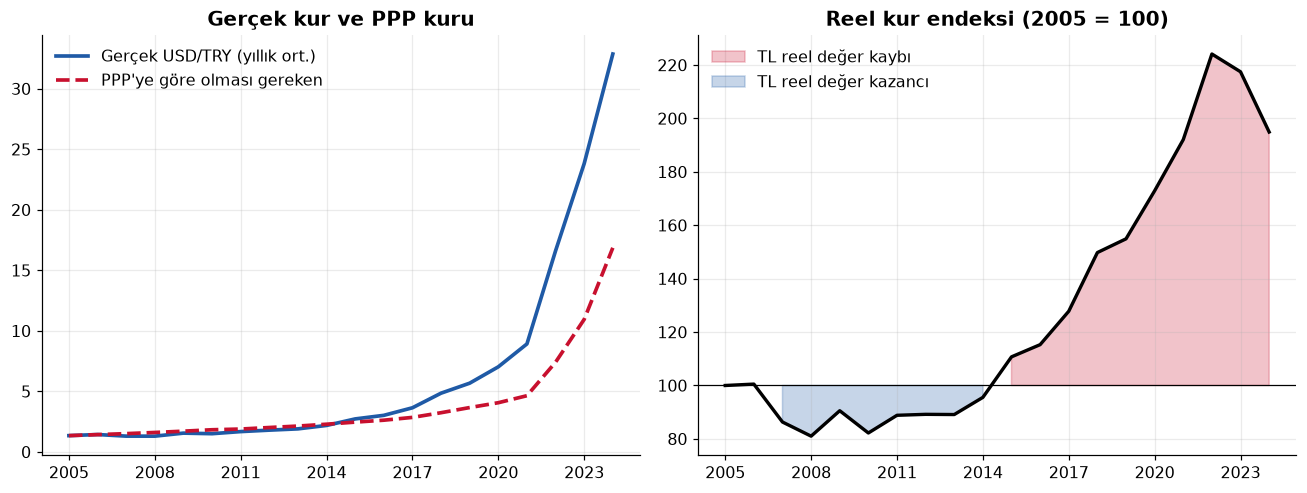

,Gerçek kur,PPP kuru,Reel kur endeksi
yil,,,
2005,1.35,1.35,100.00
2008,1.30,1.61,81.03
2011,1.68,1.89,88.84
2014,2.19,2.29,95.55
2017,3.65,2.85,127.81
2020,7.03,4.07,172.92
2023,23.82,10.95,217.48
2024,32.87,16.86,194.93


In [5]:
ortak = enflasyon[["Türkiye", "ABD"]].dropna().loc[2005:]
yillar = ortak.index
carpan = ((1 + ortak["Türkiye"] / 100) / (1 + ortak["ABD"] / 100)).loc[2006:]
ppp_kur = pd.Series(yillik_kur.loc[2005, "USD/TRY"], index=yillar)
ppp_kur.loc[2006:] = yillik_kur.loc[2005, "USD/TRY"] * carpan.cumprod()
gercek = yillik_kur.loc[yillar, "USD/TRY"]
reel_kur = 100 * gercek / ppp_kur

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.plot(yillar, gercek, lw=2.4, color=RENK["USD/TRY"], label="Gerçek USD/TRY (yıllık ort.)")
ax1.plot(yillar, ppp_kur, lw=2.4, ls="--", color=RENK["Türkiye"], label="PPP'ye göre olması gereken")
ax1.set_title("Gerçek kur ve PPP kuru")
ax1.legend(frameon=False)
for a in (ax1, ax2):
    a.set_xticks(range(2005, 2025, 3))
ax2.axhline(100, color="black", lw=0.8)
ax2.fill_between(yillar, 100, reel_kur, where=reel_kur >= 100, color=RENK["Türkiye"], alpha=0.25, label="TL reel değer kaybı")
ax2.fill_between(yillar, 100, reel_kur, where=reel_kur < 100, color=RENK["USD/TRY"], alpha=0.25, label="TL reel değer kazancı")
ax2.plot(yillar, reel_kur, lw=2.2, color="black")
ax2.set_title("Reel kur endeksi (2005 = 100)")
ax2.legend(frameon=False, loc="upper left")
kaydet(fig, "4_ppp")
plt.show()

pd.DataFrame({"Gerçek kur": gercek, "PPP kuru": ppp_kur, "Reel kur endeksi": reel_kur}).round(2).iloc[list(range(0, len(yillar), 3)) + [-1]]

## 5. 2005'teki 1.000 TL'ye ne oldu?

2005 başında elinde 1.000 TL olan birini düşünelim. Üç senaryo:

1. **Yastık altı:** Parayı TL olarak tuttu (faiz yok).
2. **Dolar:** 2005 ortalama kurundan dolar aldı, 2025 ortalama kurundan bozdurdu.
3. **Enflasyona endeksli:** Parası yalnızca enflasyon kadar büyüdü, yani alım gücü korundu.

$$\text{Gereken tutar} = 1000 \times \prod_{k=2006}^{2025} (1 + \pi_k)$$

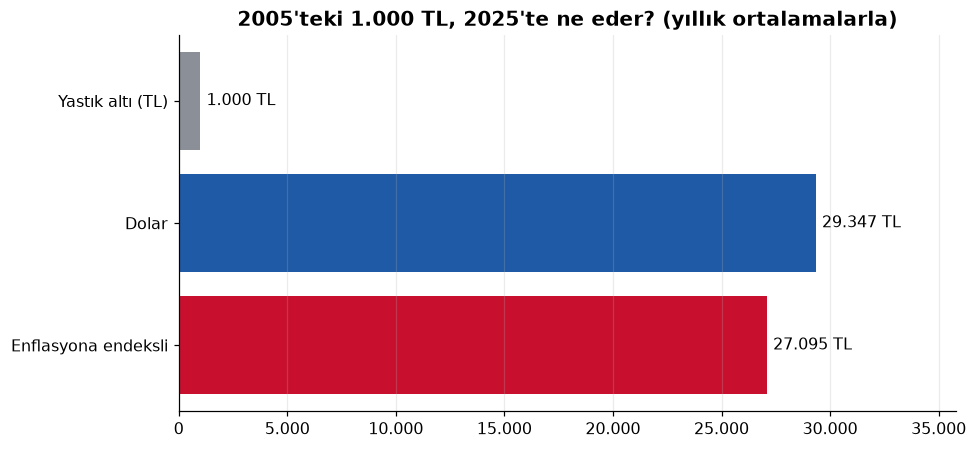

Fiyatlar 2005→2025 arasında 27.1 kat arttı.
Yastık altındaki 1.000 TL'nin bugünkü alım gücü: 36.9 TL (2005 fiyatlarıyla)
Dolarda tutmak alım gücünün %108'ini korudu.


In [6]:
tufe_carpan = (1 + enflasyon.loc[2006:2025, "Türkiye"] / 100).prod()
senaryo = pd.Series({
    "Yastık altı (TL)": 1000,
    "Dolar": 1000 / yillik_kur.loc[2005, "USD/TRY"] * yillik_kur.loc[2025, "USD/TRY"],
    "Enflasyona endeksli": 1000 * tufe_carpan,
})

fig, ax = plt.subplots(figsize=(9, 4.2))
renkler = [RENK["gri"], RENK["USD/TRY"], RENK["Türkiye"]]
cubuklar = ax.barh(senaryo.index[::-1], senaryo.values[::-1], color=renkler[::-1])
ax.bar_label(cubuklar, labels=[f"{v:,.0f} TL".replace(",", ".") for v in senaryo.values[::-1]], padding=4)
ax.set_xlim(0, senaryo.max() * 1.22)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.set_title("2005'teki 1.000 TL, 2025'te ne eder? (yıllık ortalamalarla)")
ax.grid(axis="y", visible=False)
kaydet(fig, "5_bin_tl")
plt.show()

print(f"Fiyatlar 2005→2025 arasında {tufe_carpan:.1f} kat arttı.")
print(f"Yastık altındaki 1.000 TL'nin bugünkü alım gücü: {1000 / tufe_carpan:.1f} TL (2005 fiyatlarıyla)")
print(f"Dolarda tutmak alım gücünün %{100 * senaryo['Dolar'] / senaryo['Enflasyona endeksli']:.0f}'ini korudu.")

## 6. Sonuçlar

| Bulgu | Sayı |
|---|---|
| Türkiye'de fiyatlar 2005 → 2025 | **27,1 kat** arttı |
| USD/TRY yıllık ortalama 2005 → 2025 | 1,35 → 39,57 (**29,3 kat**) |
| Ortalama enflasyon 2005–2017 / 2022–2025 | %8,5 → **%54,9** |
| Aynı yıl enflasyon–kur korelasyonu | r = **0,83** |
| Reel kur endeksi (2005 = 100) en yüksek | **224** (2022) |

1. **Ayrışma 2018'de başladı, 2022'de patladı.** 2005–2017 arasında Türkiye enflasyonu ABD'nin yaklaşık 4 katıydı; 2022–2025'te ortalama %55 ile 10 katı aştı.
2. **Kur ve enflasyon birlikte hareket ediyor.** Yıllık değişimler arasındaki korelasyon güçlü (0,83). Geçen yılın kur artışı ile bu yılın enflasyonu arasında da belirgin bir ilişki var (0,69); bu, kur geçişkenliği hipoteziyle tutarlı.
3. **PPP'ye göre TL iki dönem yaşadı.** 2007–2014 arasında TL reel olarak *değerliydi* (endeks 81–96). 2015'ten sonra hızla *değer kaybetti*, endeks 2022'de 224'e çıktı. 2023–2024'te kur artışı enflasyonun gerisinde kaldı ve TL kısmen reel değer kazandı (endeks 195'e indi).
4. **Yastık altı en kötü seçenekti.** 2005'teki 1.000 TL'nin alım gücü 2005 fiyatlarıyla 37 TL'ye düştü. Dolarda tutmak alım gücünü korudu, hatta %8 aştı.

### Sınırlılıklar
- Yıllık ortalama veri kullanıldı; yıl içindeki sert kur şokları ortalamada yumuşar.
- Göreli PPP baz yıla duyarlıdır: 2005'in "dengede" olduğu varsayılır.
- "Yastık altı" senaryosu faizi yok sayar. TL mevduat faizi eklenince sonuç değişir; bu, [kredi-faiz-hesaplayici](https://github.com/mehmetvrl32-cpu/kredi-faiz-hesaplayici) projesinin reel faiz bölümünün konusu.
- Bu çalışma eğitim amaçlıdır, yatırım tavsiyesi değildir.
